Import bibliotek
* pandas i numpy: do manipulacji i przetwarzania danych.

* sklearn: do modelowania, imputacji brakujących wartości i oceny wyników.

* LogisticRegression: wybrany model do klasyfikacji binarnej.

* accuracy_score: do oceny dokładności predykcji modelu.

* matplotlib.pyplot: do tworzenia wizualizacji danych (np. histogramów, wykresów rozkładu).

* missingno: do wizualizacji brakujących wartości w danych (np. ich rozmieszczenia, korelacji).

* seaborn: do zaawansowanych wizualizacji danych (np. heatmap, wykresów słupkowych).
* sklearn.preprocessing do standaryzacji zmiennych

In [19]:
# Importowanie bibliotek
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import missingno as msno
import seaborn as sns
from sklearn.preprocessing import StandardScaler

Wczytywanie danych i eksploracja
* Wczytuję dane treningowe (train.csv) oraz testowe (test.csv).
* Wyświetlam podstawowe informacje o strukturze danych (info) oraz statystyki opisowe.
* Sprawdzam i wizualizuję rozkład w kolumnie sii (target)

In [14]:
# Wczytywanie danych
train_csv = pd.read_csv('train.csv')
test_csv = pd.read_csv('test.csv')

# Podstawowe informacje o danych
print(train_csv.info())  # Struktura danych
print(train_csv.describe())  # Statystyki opisowe

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3960 entries, 0 to 3959
Data columns (total 82 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   id                                      3960 non-null   object 
 1   Basic_Demos-Enroll_Season               3960 non-null   object 
 2   Basic_Demos-Age                         3960 non-null   int64  
 3   Basic_Demos-Sex                         3960 non-null   int64  
 4   CGAS-Season                             2555 non-null   object 
 5   CGAS-CGAS_Score                         2421 non-null   float64
 6   Physical-Season                         3310 non-null   object 
 7   Physical-BMI                            3022 non-null   float64
 8   Physical-Height                         3027 non-null   float64
 9   Physical-Weight                         3076 non-null   float64
 10  Physical-Waist_Circumference            898 non-null    floa

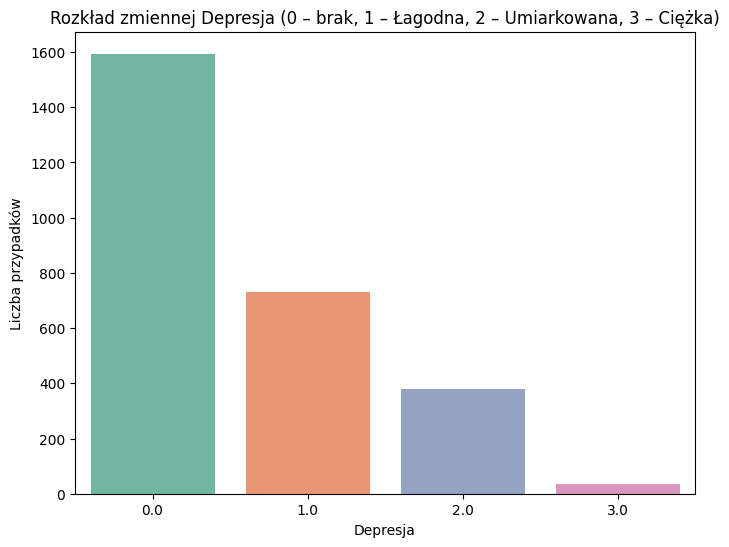

In [15]:
plt.figure(figsize=(8, 6))
sns.countplot(x='sii', data=train_csv, palette='Set2')
plt.title('Rozkład zmiennej Depresja (0 – brak, 1 – Łagodna, 2 – Umiarkowana, 3 – Ciężka)')
plt.xlabel('Depresja')
plt.ylabel('Liczba przypadków')
plt.show()

Przygotowanie danych

* wypełniam braki danych numerycznych średnią (za wyjątkiem kolumny 'sii')

* One-hot encoding na zmiennych kategorycznych

In [16]:
numeric_cols = train_csv.select_dtypes(include=[np.number]).columns
numeric_cols = numeric_cols.drop('sii', errors='ignore')  # Usuwa 'sii', jeśli istnieje
train_csv[numeric_cols] = train_csv[numeric_cols].fillna(train_csv[numeric_cols].mean())


numerical_cols = test_csv.select_dtypes(include=[np.number]).columns
test_csv[numerical_cols] = test_csv[numerical_cols].fillna(test_csv[numerical_cols].mean())

print(train_csv.loc[train_csv['sii'].isnull()])

            id Basic_Demos-Enroll_Season  Basic_Demos-Age  Basic_Demos-Sex  \
4     0016bb22                    Spring               18                1   
7     0068a485                      Fall               10                1   
8     0069fbed                    Summer               15                0   
9     0083e397                    Summer               19                1   
10    0087dd65                    Spring               11                1   
...        ...                       ...              ...              ...   
3943  fe7c87e2                    Spring               13                0   
3944  fe7f68a7                    Spring               15                1   
3950  ff0ab367                    Spring                9                0   
3956  ffa9794a                    Winter               10                0   
3959  ffef538e                    Spring               11                0   

     CGAS-Season  CGAS-CGAS_Score Physical-Season  Physical-BMI

In [18]:
train_csv = pd.get_dummies(train_csv, columns=train_csv.select_dtypes(include=['object']).columns.drop('id'))
test_csv = pd.get_dummies(test_csv, columns=test_csv.select_dtypes(include=['object']).columns.drop('id'))


Podział danych oraz trenowanie modelu
* Tworzę pipeline dla modeli XGBClassifier, RandomForestClassifier, LogisticRegression
* Piszę funkcję, która waliduje model za pomocą walidacji krzyżowej 
    * Oblicza średnią dokładność (`accuracy`) oraz odchylenie standardowe wyników.
    * Generuje raport klasyfikacji oraz macierz konfuzji dla przewidywań z walidacji krzyżowej, co     pozwala na dokładniejszą analizę skuteczności modelu.

In [20]:
train_csv = train_csv.dropna(subset=['sii'])

X_train_full = train_csv.drop(columns=['sii'])
y_train_full = train_csv['sii']

X_test = test_csv

In [21]:
# Dopasowanie kolumn w X_train i X_test
common_columns = X_train_full.columns.intersection(X_test.columns)

# Wybranie wspólnych kolumn
x_train = X_train_full[common_columns]
X_test = X_test[common_columns]


In [22]:
#zamiana wartości foat na int
# X_train_full['sii'] = train_csv['sii'].astype(int)
y_train_full = y_train_full.astype(int)

In [23]:

# Zachowanie kolumny 'id' i usunięcie jej z danych
id_column_train = x_train['id']  # Jeśli potrzebujesz 'id' z danych treningowych
id_column_test = X_test['id']    # Jeśli potrzebujesz 'id' z danych testowych

x_train = x_train.drop(columns=['id'])
X_test = X_test.drop(columns=['id'])

# Upewnienie się, że kolumny nadal się zgadzają
assert list(x_train.columns) == list(X_test.columns), "Columns in X_train and X_test do not match"


# Tworzenie instancji skalera
scaler = StandardScaler()

# Dopasowanie i przeskalowanie danych treningowych
x_train_scaled = scaler.fit_transform(x_train)

# Przeskalowanie danych testowych
X_test_scaled = scaler.transform(X_test)



In [24]:
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
#import cross_val_score
from sklearn.model_selection import cross_val_score, KFold, cross_val_predict


#funkcja do walidacji modelu
def validate_model(model, x_train, y_train, cv=5):
    """Kompleksowa walidacja modelu: cross-validation + metryki."""
    kf = KFold(n_splits=cv, shuffle=True, random_state=42)
    scores = cross_val_score(model, x_train, y_train, cv=kf, scoring='accuracy')
    print(f"Dokładność (Cross-Validation): {np.mean(scores)} (+/- {np.std(scores)})")

    # Predykcje z cross-validation (potrzebne do metryk)
    y_pred = cross_val_predict(model, x_train, y_train, cv=kf)

    print(f"Raport klasyfikacji (Cross-Validation) {model}:")
    print(classification_report(y_train, y_pred))
    print(f"Macierz konfuzji (Cross-Validation) {model}:")
    print(confusion_matrix(y_train, y_pred))
    return scores



#funkcja do znalezienia najlepszego modelu
def find_best_model(models, x_train, y_train):
    best_accuracy = 0
    best_model = None
    
    for model in models:
        accuracy = np.mean(validate_model(model, x_train, y_train))
        if accuracy > best_accuracy:
            best_accuracy = accuracy
            best_model = model
    print(f'Wybrany model: {best_model} z dokładnością {best_accuracy}')
    return best_model


#modele do testowania
models = [
    XGBClassifier(),
    RandomForestClassifier(),
    LogisticRegression(max_iter=500)
]

# Trenuj model
best_model = find_best_model(models, x_train_scaled, y_train_full)


best_model.fit(x_train_scaled, y_train_full)


# Przewiduj wyniki
predictions = best_model.predict(X_test_scaled)

# Przywróć kolumnę 'id' do wyników
results = pd.DataFrame({'id': id_column_test, 'prediction': predictions})

# Wyświetl wyniki
print(results)

Dokładność (Cross-Validation): 0.5793018321568209 (+/- 0.0226805207111525)
Raport klasyfikacji (Cross-Validation) XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, random_state=None, ...):
              precision    recall  f1-score   support

           0       0.68      0.83      0.75      1594
           1      

Dokładność (Cross-Validation): 0.5928288341184162 (+/- 0.017096431061925196)
Raport klasyfikacji (Cross-Validation) LogisticRegression(max_iter=500):
              precision    recall  f1-score   support

           0       0.68      0.86      0.76      1594
           1       0.38      0.24      0.30       730
           2       0.31      0.16      0.21       378
           3       0.18      0.15      0.16        34

    accuracy                           0.59      2736
   macro avg       0.39      0.35      0.36      2736
weighted avg       0.54      0.59      0.55      2736

Macierz konfuzji (Cross-Validation) LogisticRegression(max_iter=500):
[[1377  156   53    8]
 [ 477  178   71    4]
 [ 177  128   62   11]
 [   4   12   13    5]]
Wybrany model: LogisticRegression(max_iter=500) z dokładnością 0.5928288341184162
          id  prediction
0   00008ff9           0
1   000fd460           0
2   00105258           0
3   00115b9f           0
4   0016bb22           0
5   001f3379        

## Wyniki walidacji krzyżowej

### XGBClassifier
- **Dokładność:** 57.93% (+/- 2.27%)
- **F1-Score (weighted avg):** 0.55
- **Najlepsza klasa:** Klasa `0` (Precision: 0.68, Recall: 0.83)
- **Problematyczne klasy:** Klasy `2` i `3` (niski Recall i F1-Score)

### RandomForestClassifier
- **Dokładność:** 59.10% (+/- 1.64%)
- **F1-Score (weighted avg):** 0.54
- **Najlepsza klasa:** Klasa `0` (Precision: 0.66, Recall: 0.89)
- **Problematyczne klasy:** Klasa `3` (Recall: 0.00)

### LogisticRegression
- **Dokładność:** 59.28% (+/- 1.71%)
- **F1-Score (weighted avg):** 0.55
- **Najlepsza klasa:** Klasa `0` (Precision: 0.68, Recall: 0.86)
- **Problematyczne klasy:** Klasy `1` i `3` (niskie wartości Recall)

---

### Wnioski
- LogisticRegression osiągnęło najwyższą dokładność i najlepsze wyniki dla najtrudniejszych klas.
- Klasa `0` jest najlepiej rozpoznawana przez wszystkie modele.
- Konieczna jest poprawa w rozpoznawaniu klas `2` i `3`.


Zapis wyników do zgłoszeniowego CSV

In [25]:
results.to_csv('results.csv', index=False)